
Slide 7: Variance of the sample mean
    n    Theory: 1/n     Simulation
    1         1.0000         1.0000
    5         0.2000         0.1976
   20         0.0500         0.0501
  100         0.0100         0.0099


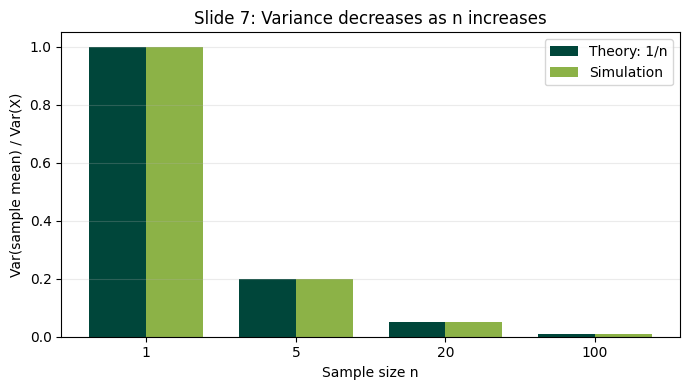

In [36]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# Shared settings
# ============================================================

BASE_SEED = 2121
REPETITIONS = 20_000

DARK_GREEN = "#00463A"
LIGHT_GREEN = "#8CB247"

# Set to True to save a PNG copy of each figure.
SAVE_FIGURES = False


def show_figure(fig, filename):
    """Optionally save a figure, then display it."""
    if SAVE_FIGURES:
        fig.savefig(filename, dpi=200, bbox_inches="tight")
        print(f"Saved: {filename}")

    plt.show()
    plt.close(fig)


def normal_density(x, mean, standard_deviation):
    """Return the density of a normal distribution."""
    z = (x - mean) / standard_deviation
    return (
        np.exp(-0.5 * z**2)
        / (standard_deviation * np.sqrt(2 * np.pi))
    )


# ============================================================
# Slide 7: Variance of the sample mean
# ============================================================

def slide_7_variance():
    """Compare simulated variance ratios with the theoretical 1/n."""
    rng = np.random.default_rng(BASE_SEED + 7)

    sample_sizes = [1, 5, 20, 100]

    # For X ~ Uniform(0, 10), Var(X) = (10 - 0)^2 / 12.
    population_variance = 100 / 12

    theoretical_ratios = []
    simulated_ratios = []

    print("\nSlide 7: Variance of the sample mean")
    print(f"{'n':>5} {'Theory: 1/n':>14} {'Simulation':>14}")

    for n in sample_sizes:
        # Each row represents a new independent sample of size n.
        samples = rng.uniform(
            0, 10, size=(REPETITIONS, n)
        )

        # One sample mean is calculated for each row.
        sample_means = samples.mean(axis=1)

        theory = 1 / n
        simulation = (
            sample_means.var(ddof=1) / population_variance
        )

        theoretical_ratios.append(theory)
        simulated_ratios.append(simulation)

        print(f"{n:5d} {theory:14.4f} {simulation:14.4f}")

    positions = np.arange(len(sample_sizes))
    width = 0.38

    fig, ax = plt.subplots(figsize=(7, 4))

    ax.bar(
        positions - width / 2,
        theoretical_ratios,
        width,
        color=DARK_GREEN,
        label="Theory: 1/n",
    )
    ax.bar(
        positions + width / 2,
        simulated_ratios,
        width,
        color=LIGHT_GREEN,
        label="Simulation",
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(sample_sizes)
    ax.set_xlabel("Sample size n")
    ax.set_ylabel("Var(sample mean) / Var(X)")
    ax.set_title("Slide 7: Variance decreases as n increases")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)

    fig.tight_layout()
    show_figure(fig, "slide_07_variance.png")


# ============================================================
# Run the six teaching demonstrations
# ============================================================

slide_7_variance()


Slide 8: Individual observations versus sample means
Individuals: mean = 5.010, SD = 2.891
Sample means (n=4): mean = 5.010, SD = 1.449
Sample means (n=30): mean = 5.002, SD = 0.529


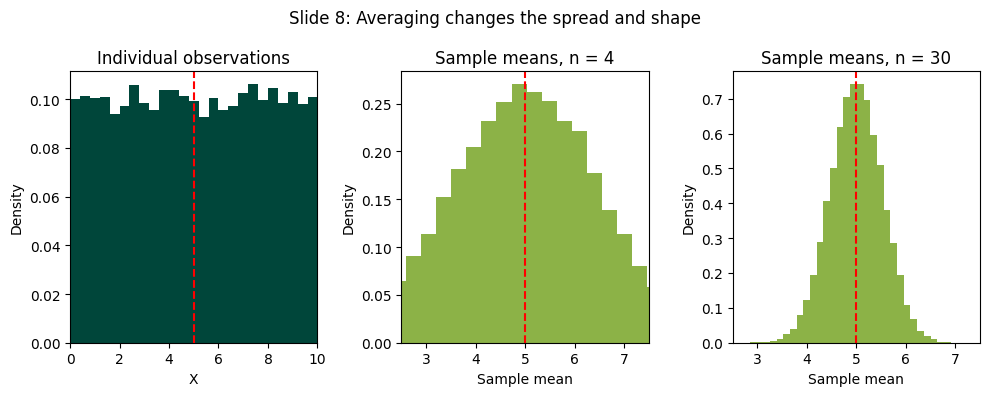

In [37]:
# ============================================================
# Slide 8: Individual observations versus sample means
# ============================================================

def slide_8_individuals_and_means():
    """Contrast uniform observations with means of samples of size 30."""
    rng = np.random.default_rng(BASE_SEED + 8)
    n = 30

    # These are individual observations from Uniform(0, 10).
    individuals = rng.uniform(0, 10, size=REPETITIONS)

    # Each row is a fresh sample; its average is one sample mean.
    samples = rng.uniform(
        0, 10, size=(REPETITIONS, n)
    )
    sample_means = samples.mean(axis=1)

    # Each row is a fresh sample; its average is one sample mean.
    samples_4 = rng.uniform(
        0, 10, size=(REPETITIONS, 4)
    )
    sample_4_means = samples_4.mean(axis=1)

    print("\nSlide 8: Individual observations versus sample means")
    print(
        f"Individuals: mean = {individuals.mean():.3f}, "
        f"SD = {individuals.std(ddof=1):.3f}"
    )
    print(
        f"Sample means (n=4): mean = {sample_4_means.mean():.3f}, "
        f"SD = {sample_4_means.std(ddof=1):.3f}"
    )
    print(
        f"Sample means (n=30): mean = {sample_means.mean():.3f}, "
        f"SD = {sample_means.std(ddof=1):.3f}"
    )

    fig, axes = plt.subplots(1, 3, figsize=(10, 4))

    axes[0].hist(
        individuals, bins=25, density=True, color=DARK_GREEN
    )
    axes[0].set_xlim(0, 10)
    axes[0].set_title("Individual observations")
    axes[0].set_xlabel("X")

    axes[1].hist(
        sample_4_means, bins=30, density=True, color=LIGHT_GREEN
    )
    axes[1].set_xlim(2.5, 7.5)
    axes[1].set_title("Sample means, n = 4")
    axes[1].set_xlabel("Sample mean")

    axes[2].hist(
        sample_means, bins=30, density=True, color=LIGHT_GREEN
    )
    axes[2].set_xlim(2.5, 7.5)
    axes[2].set_title("Sample means, n = 30")
    axes[2].set_xlabel("Sample mean")

    for ax in axes:
        # Both distributions are centred near the population mean.
        ax.axvline(5, color="red", linestyle="--")
        ax.set_ylabel("Density")

    fig.suptitle(
        "Slide 8: Averaging changes the spread and shape"
    )
    fig.tight_layout()
    show_figure(fig, "slide_08_individuals_and_means.png")


slide_8_individuals_and_means()

Slides 12 and 13: Shared fair-coin sequences

In [38]:

# ============================================================
# Slides 12 and 13: Shared fair-coin sequences
# ============================================================

def make_coin_paths():
    """Generate three independent sequences of 1,000 fair-coin flips."""
    rng = np.random.default_rng(BASE_SEED + 12)

    # 1 represents heads; 0 represents tails.
    return rng.binomial(
        1, 0.5, size=(3, 1000)
    )


def slide_12_coin_table(coin_paths):
    """Display checkpoints from the first coin-flip sequence."""
    first_path = coin_paths[0]
    cumulative_heads = np.cumsum(first_path)

    checkpoints = [1, 10, 50, 200, 1000]

    print("\nSlide 12: Running averages of one coin-flip sequence")
    print(
        f"{'Flips n':>10} "
        f"{'Heads':>10} "
        f"{'Running average':>18}"
    )

    for n in checkpoints:
        heads = int(cumulative_heads[n - 1])
        running_average = heads / n

        print(
            f"{n:10d} "
            f"{heads:10d} "
            f"{running_average:18.3f}"
        )

In [39]:
coin_paths = make_coin_paths()
slide_12_coin_table(coin_paths)


Slide 12: Running averages of one coin-flip sequence
   Flips n      Heads    Running average
         1          0              0.000
        10          4              0.400
        50         23              0.460
       200         97              0.485
      1000        479              0.479


In [40]:

def slide_13_running_averages(coin_paths):
    """Plot running head proportions for all three sequences."""
    flip_numbers = np.arange(1, 1001)

    colours = [DARK_GREEN, LIGHT_GREEN, "black"]
    markers = ["o", "s", "^"]

    fig, ax = plt.subplots(figsize=(8.5, 4.6))

    for index, path in enumerate(coin_paths):
        # At each n, divide the number of heads so far by n.
        running_average = np.cumsum(path) / flip_numbers

        ax.plot(
            flip_numbers,
            running_average,
            color=colours[index],
            marker=markers[index],
            markevery=[0, 1, 4, 9, 19, 49, 99, 199, 499, 999],
            markersize=4,
            linewidth=1.4,
            label=f"Simulation {index + 1}",
        )

    ax.axhline(
        0.5,
        color="red",
        linestyle="--",
        linewidth=2,
        label="True mean = 0.5",
    )

    ax.set_xscale("log")
    ax.set_xlim(1, 1000)

    # A genuine sequence has a running average of either 0 or 1 at n = 1.
    ax.set_ylim(-0.03, 1.03)

    ax.set_xticks([1, 10, 100, 1000])
    ax.set_xticklabels(["1", "10", "100", "1000"])
    ax.set_xlabel("Number of coin flips n")
    ax.set_ylabel("Running proportion of heads")
    ax.set_title("Slide 13: Running averages of fair-coin flips")
    ax.grid(alpha=0.3)

    # Keep the legend below the plot, away from the simulated paths.
    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.22),
        ncol=2,
        frameon=False,
    )
    fig.subplots_adjust(
        left=0.11, right=0.98, top=0.90, bottom=0.32
    )

    show_figure(fig, "slide_13_running_averages.png")

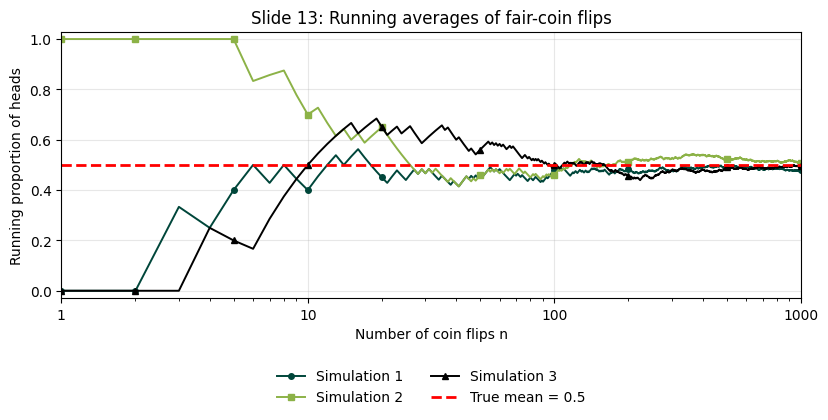

In [41]:
slide_13_running_averages(coin_paths)

Slides 20 and 21

In [42]:

# ============================================================
# Slides 20 and 21: A reusable CLT plotting function
# ============================================================

def plot_clt_simulation(
    sampler,
    population_mean,
    population_sd,
    x_ranges,
    slide_number,
    population_name,
):
    """
    Compare the original population with sample means for n = 5 and 30.

    sampler(shape) must generate independent observations in the
    requested array shape.
    """
    original = sampler((REPETITIONS,))

    # Every row is an independently generated sample.
    means_5 = sampler((REPETITIONS, 5)).mean(axis=1)
    means_30 = sampler((REPETITIONS, 30)).mean(axis=1)

    datasets = [original, means_5, means_30]
    labels = [
        "Original X",
        "Sample means: n = 5",
        "Sample means: n = 30",
    ]
    sample_sizes = [None, 5, 30]

    print(f"\nSlide {slide_number}: {population_name} population")
    print(f"Population mean: {population_mean:.3f}")
    print(f"Population SD:   {population_sd:.3f}")
    print(
        f"SD of means, n = 5:  "
        f"simulated {means_5.std(ddof=1):.3f}; "
        f"theoretical {population_sd / np.sqrt(5):.3f}"
    )
    print(
        f"SD of means, n = 30: "
        f"simulated {means_30.std(ddof=1):.3f}; "
        f"theoretical {population_sd / np.sqrt(30):.3f}"
    )

    fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))

    for ax, data, label, x_range, n in zip(
        axes, datasets, labels, x_ranges, sample_sizes
    ):
        ax.hist(
            data,
            bins=45,
            density=True,
            color=DARK_GREEN if n is None else LIGHT_GREEN,
            alpha=0.9,
        )

        # Red marks the population mean on all three panels.
        ax.axvline(
            population_mean,
            color="red",
            linestyle="--",
            linewidth=1.4,
        )

        if n is not None:
            # CLT normal approximation: mean mu, SD sigma / sqrt(n).
            standard_error = population_sd / np.sqrt(n)
            x = np.linspace(x_range[0], x_range[1], 300)

            ax.plot(
                x,
                normal_density(
                    x, population_mean, standard_error
                ),
                color="black",
                linestyle="--",
                linewidth=1.6,
                label="Normal approximation",
            )

        ax.set_xlim(x_range)
        ax.set_title(label)
        ax.set_xlabel("Value")
        ax.set_ylabel("Density")

    axes[1].legend(loc="upper left", fontsize=8, frameon=False)

    fig.suptitle(
        f"Slide {slide_number}: CLT with a "
        f"{population_name} population"
    )
    fig.tight_layout()

    show_figure(
        fig,
        f"slide_{slide_number}_{population_name.lower()}_clt.png",
    )


def slide_20_uniform_clt():
    """Illustrate the CLT for X ~ Uniform(0, 10)."""
    rng = np.random.default_rng(BASE_SEED + 20)

    # Uniform(0, 10): mu = 5 and sigma = 10 / sqrt(12).
    plot_clt_simulation(
        sampler=lambda shape: rng.uniform(
            0, 10, size=shape
        ),
        population_mean=5,
        population_sd=10 / np.sqrt(12),
        x_ranges=[(0, 10), (1, 9), (3, 7)],
        slide_number=20,
        population_name="Uniform",
    )


Slide 20: Uniform population
Population mean: 5.000
Population SD:   2.887
SD of means, n = 5:  simulated 1.292; theoretical 1.291
SD of means, n = 30: simulated 0.528; theoretical 0.527


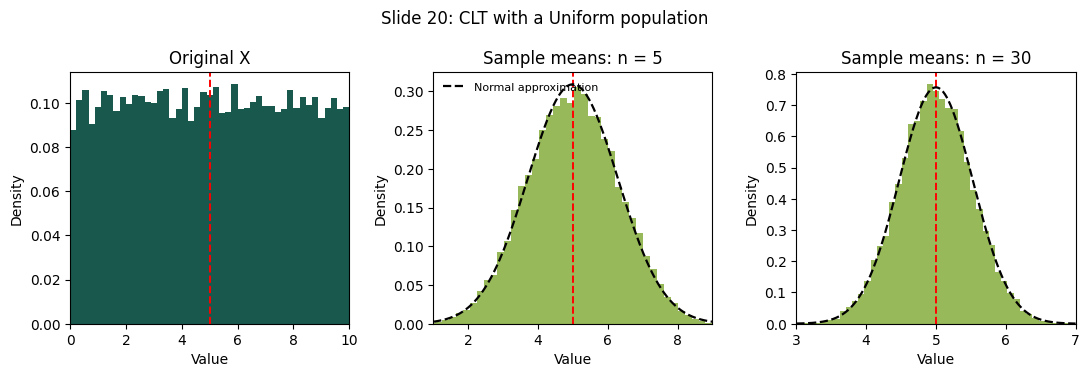

In [43]:
slide_20_uniform_clt()

In [44]:
def slide_21_exponential_clt():
    """Illustrate the CLT for X ~ Exponential(scale=1)."""
    rng = np.random.default_rng(BASE_SEED + 21)

    # Exponential(scale=1): mu = 1 and sigma = 1.
    plot_clt_simulation(
        sampler=lambda shape: rng.exponential(
            scale=1, size=shape
        ),
        population_mean=1,
        population_sd=1,
        x_ranges=[(0, 5.5), (0, 3), (0.3, 1.7)],
        slide_number=21,
        population_name="Exponential",
    )


Slide 21: Exponential population
Population mean: 1.000
Population SD:   1.000
SD of means, n = 5:  simulated 0.447; theoretical 0.447
SD of means, n = 30: simulated 0.182; theoretical 0.183


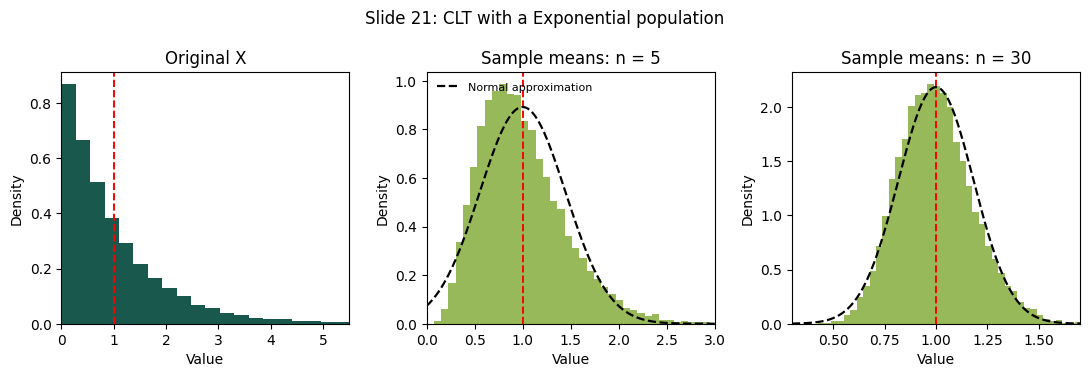

In [45]:
slide_21_exponential_clt()